In [2]:
from mylib.statistic_test import *

code_id = "0883 - Proximity interaction"
loc = join(figdata, "Dsp", code_id)
mkdir(loc)

d:\Softwares\Anaconda2025\envs\maze\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


        D:\Data\FigData\Dsp\0883 - Proximity interaction is already existed!


False

In [74]:
def calc_apvc(mouse):
    if os.path.exists(os.path.join(loc, f"{mouse}_apvc.pkl")):
        with open(os.path.join(loc, f"{mouse}_apvc.pkl"), "rb") as f:
            apvc = pickle.load(f)
    else:
        apvc = np.zeros((144, 3, 3, 7)) * np.nan
        file_idx = np.where(f2['MiceID'] == mouse)[0][7:]
        for s, idx in tqdm(enumerate(file_idx)):
            if os.path.exists(f2['Trace File'][idx]) == False:
                print(f"{f2['Trace File'][idx]} does not exist.")
                continue
            
            with open(f2['Trace File'][idx], "rb") as f:
                trace = pickle.load(f)
                
            nodes = [6, 7, 11]
            rts = [8, 9, 7]
            targ_nodes1 = [0, 0, 0]
            targ_nodes2 = [2, 3, 1]
            for aa, node, node_targ, node_targ2, rt in zip(np.arange(3), nodes, targ_nodes1, targ_nodes2, rts):
                nds = [node, node_targ, node_targ2]
                n = 0
                for i in range(2):
                    for j in range(i+1, 3):
                        if s >= 0:
                            for b in CP_DSPs[1][rt].astype(int):
                                sonbins = Father2SonGraph[b]
                                apvc[b-1, aa, n, s] = np.nanmean(np.asarray([
                                    np.corrcoef(
                                        trace[f'node {nds[i]}']['smooth_map_all'][:, sb-1], 
                                        trace[f'node {nds[j]}']['smooth_map_all'][:, sb-1]
                                    )[0, 1] for sb in sonbins
                                ]))   
                        else:             
                            if j >= 2:
                                continue
                            nd_i = nds[i] - 5
                            nd_j = nds[j] - 5
                            for b in CP_DSPs[1][rt].astype(int):
                                sonbins = Father2SonGraph[b]
                                apvc[b-1, aa, n, s] = np.nanmean(np.asarray([
                                    np.corrcoef(
                                        trace[f'node {nd_i}']['smooth_map_all'][:, sb-1], 
                                        trace[f'node {nd_j}']['smooth_map_all'][:, sb-1]
                                    )[0, 1] for sb in sonbins
                                ]))   
                        n += 1
                        
        with open(os.path.join(loc, f"{mouse}_apvc.pkl"), "wb") as f:
            pickle.dump(apvc, f)
            
    return apvc

calc_apvc(10275)
calc_apvc(10276)
pass

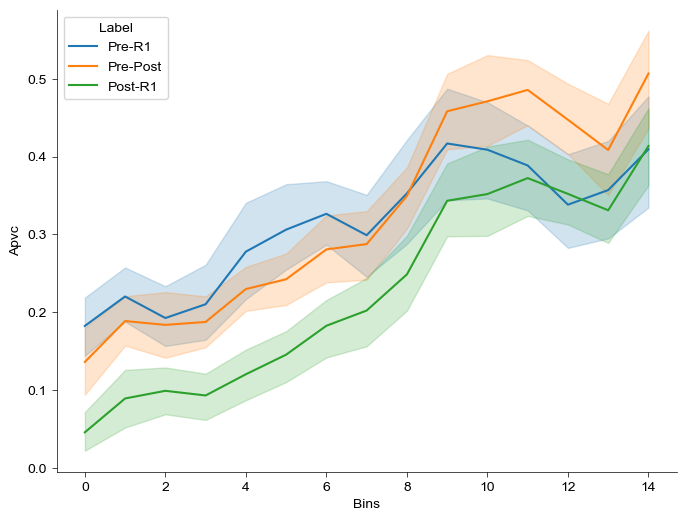

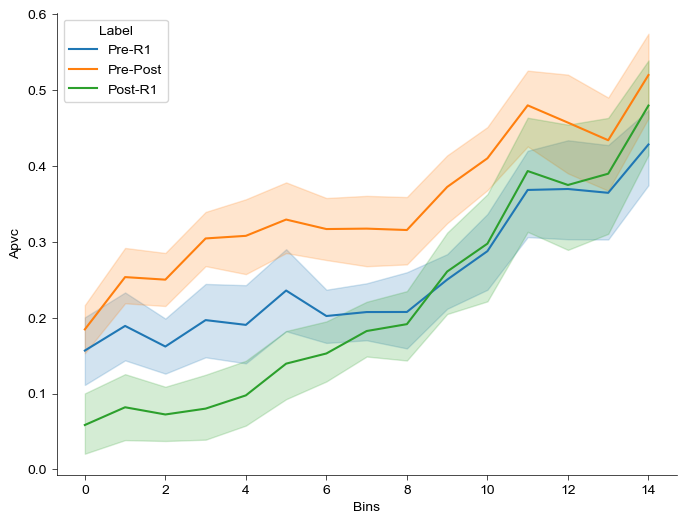

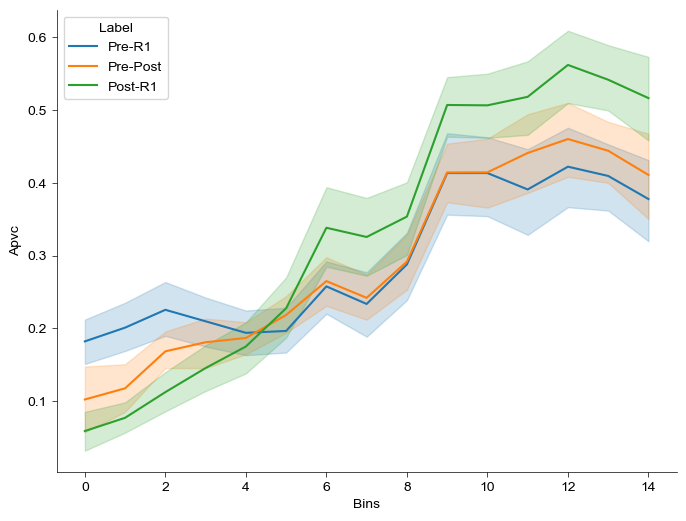

In [77]:
if exists(join(figdata, f"{code_id}.pkl")) == False:
    Data = {
        "MiceID": [],
        "Apvc": [],
        "Bins": [],
        "Session": [],
        "Label": [],
        "Route": []
    }
    
    for mouse in [10275, 10276]:
        apvc = calc_apvc(mouse)
        for n, rt, rt2 in zip([0, 1, 2], [8, 9, 7], [1, 2, 4]):
            for s in range(7):
                bins = np.arange(15)
                n_bins = len(bins)
                Data["MiceID"].append(np.repeat(mouse, n_bins*3))
                Data["Apvc"].append(np.concatenate([apvc[CP_DSPs[1][rt]-1, n, d, s][bins] for d in range(3)]))
                Data["Bins"].append(np.concatenate([bins]*3))
                Data["Session"].append(np.repeat(s, n_bins*3))
                Data["Label"].append(np.concatenate([["Pre-R1"]*n_bins, ["Pre-Post"]*n_bins, ["Post-R1"]*n_bins]))
                Data["Route"].append(np.repeat(f"R{rt2+1}", n_bins*3))
                
    for key in Data.keys():
        Data[key] = np.concatenate(Data[key])
        
    with open(join(figdata, f"{code_id}.pkl"), "wb") as f:
        pickle.dump(Data, f)
    
    D = pd.DataFrame(Data)
    D.to_excel(join(figdata, f"{code_id}.xlsx"), index=False)
    print(len(D))
else:
    with open(join(figdata, f"{code_id}.pkl"), "rb") as f:
        Data = pickle.load(f)


for rt in ['R2', 'R3', 'R5']:
    fig = plt.figure(figsize=(8, 6))
    subdata_rt = SubDict(Data, Data.keys(), np.where(Data['Route'] == rt)[0])
    ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
    sns.lineplot(
        x="Bins",
        y="Apvc",
        hue="Label",
        data=subdata_rt,
        ax=ax
    )
    plt.show()

In [32]:
with open(f2['Trace File'][47], "rb") as f:
    trace = pickle.load(f)
X, routes = get_lapwise_ratemap(trace)
corr = np.zeros((X.shape[0], X.shape[0]))

for rt_i in tqdm(range(10-1)):
    for rt_j in range(rt_i+1, 10):
        idx = np.where((routes == rt_i)|(routes == rt_j))[0]
        bin = np.intersect1d(CP_DSPs[1][rt_i], CP_DSPs[1][rt_j])
        corr[np.ix_(idx, idx)] = np.nanmean(np.stack([np.corrcoef(X[idx, sb-1, :]) for sb in np.array(Father2SonGraph[bin[0]])], axis=2), axis=2)

d:\Softwares\Anaconda2025\envs\maze\Lib\site-packages\mazepy\datastruc\neuact.py:1123: RuntimeWarning: invalid value encountered in divide
  firing_rate = spike_counts/(occu_time/1000)
100%|██████████| 9/9 [00:00<00:00, 43.78it/s]


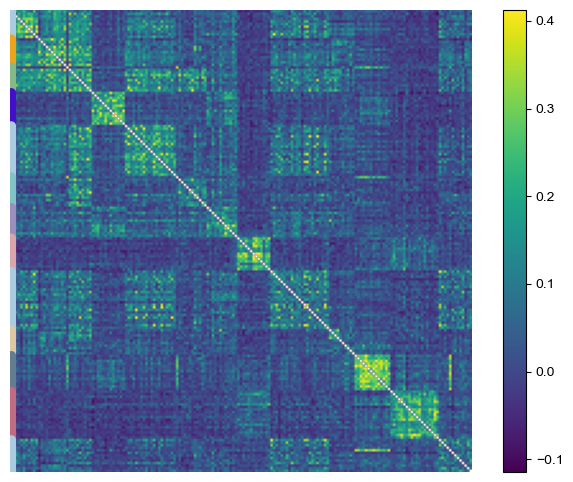

In [34]:
np.fill_diagonal(corr, np.nan)
fig = plt.figure(figsize=(8, 6))
ax = Clear_Axes(plt.axes())
im = ax.imshow(corr,
    vmax=np.nanmax(corr)*0.8
)
ax.scatter(
    np.zeros(X.shape[0]),
    np.arange(X.shape[0]),
    c=DSPPaletteRGBA[routes]
)
plt.colorbar(im)